### Data visualization task

### Load anyone dataset and do all types of Data Visualization along with Insights and submit the presentation in PPT format.

### Loading laptop dataset from kaggle

In [63]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
Laptop_sales=pd.read_csv("Laptop_data.csv")
Laptop_sales

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Total_items_sold
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832,1247
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232,1511
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000,2645
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360,614
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080,1044
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,1298.0,Lenovo,2 in 1 Convertible,14,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,33992.6400,2275
1299,1299.0,Lenovo,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,79866.7200,1717
1300,1300.0,Lenovo,Notebook,14,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,12201.1200,2930
1301,1301.0,HP,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,40705.9200,2545


In [4]:
Laptop_sales.columns # need to delete unanamed columns

Index(['Unnamed: 0', 'Company', 'TypeName', 'Inches', 'ScreenResolution',
       'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price',
       'Total_items_sold'],
      dtype='object')

In [6]:
Laptop_sales.shape #13 columns and 1303 rows

(1303, 13)

In [11]:
Laptop_sales.describe()

,Unnamed: 0,Price,Total_items_sold
count,1273.000000,1273.000000,1303.000000
mean,652.674784,59955.814073,2020.035303
std,376.493027,37332.251005,672.781366
min,0.000000,9270.720000,56.000000
25%,327.000000,31914.720000,1454.500000
50%,652.000000,52161.120000,2213.000000
75%,980.000000,79333.387200,2597.000000
max,1302.000000,324954.720000,3019.000000


In [12]:
Laptop_sales.isna().sum() # need to remove 30 null entries

Unnamed: 0          30
Company             30
TypeName            30
Inches              30
ScreenResolution    30
Cpu                 30
Ram                 30
Memory              30
Gpu                 30
OpSys               30
Weight              30
Price               30
Total_items_sold     0
dtype: int64

In [13]:
Laptop_sales.dtypes #need to change the data types of Inches

Unnamed: 0          float64
Company              object
TypeName             object
Inches               object
ScreenResolution     object
Cpu                  object
Ram                  object
Memory               object
Gpu                  object
OpSys                object
Weight               object
Price               float64
Total_items_sold      int64
dtype: object

In [64]:
del Laptop_sales ["Unnamed: 0"] #deleting a column named unnamed

In [65]:
Laptop_sales.dropna(axis=0,inplace=True) #deleting null values first

In [42]:
Laptop_sales.shape #Total 1273 rows and 12 features

(1273, 12)

In [44]:
Laptop_sales.duplicated().sum() #no duplicates after deleting nulls

np.int64(0)

In [66]:
Laptop_sales["Inches"].replace("?","0",inplace=True)

C:\Users\Q848957\AppData\Local\Temp\ipykernel_29680\1642312448.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  Laptop_sales["Inches"].replace("?","0",inplace=True)


In [67]:
Laptop_sales["Inches"]=Laptop_sales["Inches"].astype("float64")

In [248]:

Laptop_sales

ValueError: Unknown format code 'f' for object of type 'str'

In [287]:
Laptop_sales["Price"]=Laptop_sales["Price"].str.replace(r"[/$]","",regex=True)
Laptop_sales["Price"]=Laptop_sales["Price"].astype("float64")
Laptop_sales["Price_million"]=Laptop_sales["Price"].apply(lambda x: x/100000)
Laptop_sales



,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Total_items_sold,Price_million
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.68,1247,0.713787
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.52,1511,0.478955
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.00,2645,0.306360
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.34,614,1.351953
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.81,1044,0.960958
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,Lenovo,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,33992.64,2275,0.339926
1299,Lenovo,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,79866.72,1717,0.798667
1300,Lenovo,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,12201.12,2930,0.122011
1301,HP,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,40705.92,2545,0.407059


In [272]:
del Laptop_sales["Price_dollars"]
Laptop_sales
Laptop_sales["Price"]=Laptop_sales["Price"].astype("float64")

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Total_items_sold
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,$71378.68,1247
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,$47895.52,1511
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,$30636.00,2645
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,$135195.34,614
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,$96095.81,1044
...,...,...,...,...,...,...,...,...,...,...,...,...
1298,Lenovo,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,$33992.64,2275
1299,Lenovo,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,$79866.72,1717
1300,Lenovo,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,$12201.12,2930
1301,HP,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,$40705.92,2545


In [276]:
print(Laptop_price["Price"].dtype)

object


In [275]:
Laptop_price["Price_Million"] = Laptop_price["Price"] / 1000000

TypeError: unsupported operand type(s) for /: 'str' and 'int'

1.Discrete features are Company, typename, screen resolution, CPU, Ram, memory, GPU, Opsys

2. Continous features are Inches, weight, Price, total itemssold

<Axes: xlabel='count', ylabel='Company'>

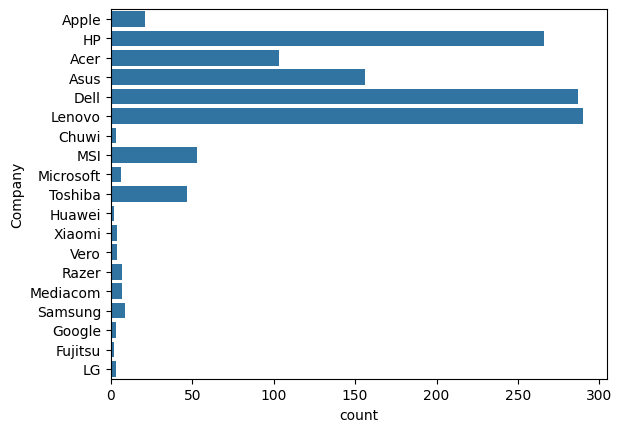

In [70]:
sns.countplot(data=Laptop_sales,y="Company") # This just shows which company has more models we can use 

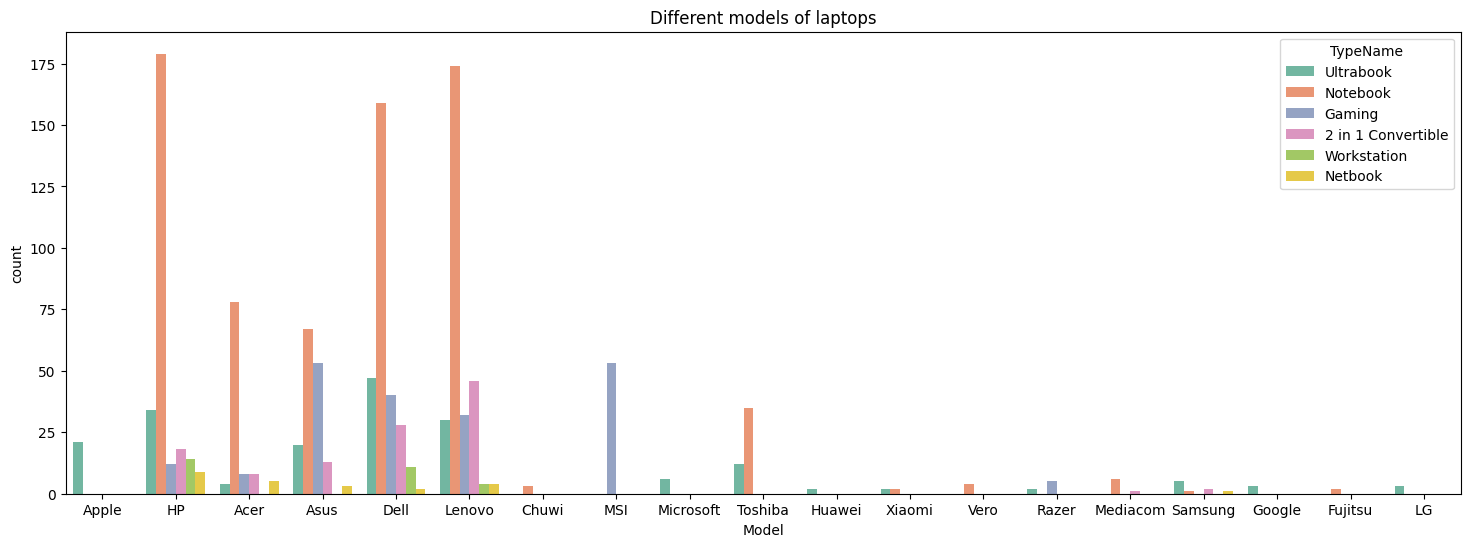

In [433]:

plt.figure(figsize=(18, 6))
sns.countplot(data=Laptop_sales,x="Company",hue="TypeName",palette="Set2")
plt.xlabel("Model")
plt.title("Different models of laptops")
plt.show()



In [115]:
Company=Laptop_sales["Company"].value_counts()
Company

Company
Lenovo       290
Dell         287
HP           266
Asus         156
Acer         103
MSI           53
Toshiba       47
Apple         21
Samsung        9
Mediacom       7
Razer          7
Microsoft      6
Vero           4
Xiaomi         4
Chuwi          3
LG             3
Google         3
Huawei         2
Fujitsu        2
Name: count, dtype: int64

In [117]:
Model=Laptop_sales[["Company","TypeName"]].nunique()
Model

Company     19
TypeName     6
dtype: int64

In [142]:
Company_models=pd.DataFrame(Laptop_sales.groupby(by=["Company","TypeName"])["ScreenResolution"].nunique())
Company_models


ScreenResolution
Company   TypeName                            
Acer      2 in 1 Convertible                 2
          Gaming                             2
          Netbook                            2
          Notebook                           6
          Ultrabook                          1
Apple     Ultrabook                          5
Asus      2 in 1 Convertible                 6
          Gaming                             3
          Netbook                            1
          Notebook                           7
          Ultrabook                          4
Chuwi     Notebook                           2
Dell      2 in 1 Convertible                 4
          Gaming                             7
          Netbook                            1
          Notebook                           8
          Ultrabook                         10
          Workstation                        5
Fujitsu   Notebook                           1
Google    Ultrabook                          1
HP        2 in 1 Convertible                 7
          Gaming                             2
          Netbook                            2
          Notebook                          10
          Ultrabook                         10
          Workstation                        3
Huawei    Ultrabook                          1
LG        Ultrabook                          2
Lenovo    2 in 1 Convertible                 8
          Gaming                             3
          Netbook                            4
          Notebook                           8
          Ultrabook                          9
          Workstation                        2
MSI       Gaming                             4
Mediacom  2 in 1 Convertible                 1
          Notebook                           3
Microsoft Ultrabook                          1
Razer     Gaming                             2
          Ultrabook                          2
Samsung   2 in 1 Convertible                 2
          Netbook                            1
          Notebook                           1
          Ultrabook                          2
Toshiba   Notebook                           5
          Ultrabook                          4
Vero      Notebook                           4
Xiaomi    Notebook                           1
          Ultrabook                          1

In [436]:
plt.figure(figsize=(16, 6))
sns.countplot(data=Company_models,x="Company",y="ScreenResolution",hue="TypeName",palette="Set2")
plt.show()

TypeError: Cannot pass values for both `x` and `y`.

<Figure size 1600x600 with 0 Axes>

In [177]:
ScreenResolution=Laptop_sales["ScreenResolution"].value_counts().head(5)
ScreenResolution

ScreenResolution
Full HD 1920x1080                            495
1366x768                                     274
IPS Panel Full HD 1920x1080                  226
IPS Panel Full HD / Touchscreen 1920x1080     52
Full HD / Touchscreen 1920x1080               45
Name: count, dtype: int64

([<matplotlib.patches.Wedge at 0x18a332c6890>,
 [Text(0.16081657418051515, 1.0881810646527732, 'Full HD 1920x1080'),
  Text(-0.968054657004467, -0.5223697742518837, '1366x768'),
  Text(0.39006553985843684, -1.028517804714603, 'IPS Panel Full HD 1920x1080'),
  Text(1.0094798820261102, -0.43697868115567245, 'IPS Panel Full HD / Touchscreen 1920x1080'),
  Text(1.0907947685942165, -0.14200976307102828, 'Full HD / Touchscreen 1920x1080')],
 [Text(0.08771813137119007, 0.5935533079924217, '45.3%'),
  Text(-0.5280298129115274, -0.2849289677737547, '25.1%'),
  Text(0.21276302174096554, -0.5610097116625107, '20.7%'),
  Text(0.55062539019606, -0.23835200790309405, '4.8%'),
  Text(0.5949789646877545, -0.07745987076601542, '4.1%')])

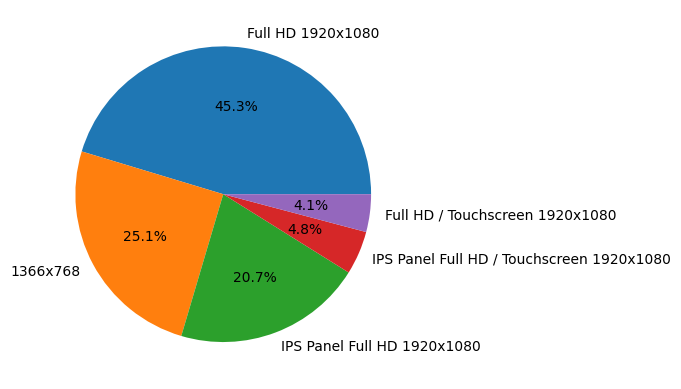

In [179]:

plt.pie(x=ScreenResolution,labels=ScreenResolution.index,autopct="%1.1f%%")

In [189]:
Company_models=pd.DataFrame(Laptop_sales.groupby(by=["Company","TypeName"])["Cpu"].nunique())
Company_models


Cpu
Company   TypeName               
Acer      2 in 1 Convertible    7
          Gaming                3
          Netbook               3
          Notebook             22
          Ultrabook             4
Apple     Ultrabook            14
Asus      2 in 1 Convertible    7
          Gaming                8
          Netbook               2
          Notebook             21
          Ultrabook             7
Chuwi     Notebook              3
Dell      2 in 1 Convertible   12
          Gaming                5
          Netbook               2
          Notebook             22
          Ultrabook            13
          Workstation           5
Fujitsu   Notebook              2
Google    Ultrabook             2
HP        2 in 1 Convertible   10
          Gaming                2
          Netbook               5
          Notebook             35
          Ultrabook            11
          Workstation           7
Huawei    Ultrabook             2
LG        Ultrabook             2
Lenovo    2 in 1 Convertible   13
          Gaming                5
          Netbook               3
          Notebook             37
          Ultrabook             9
          Workstation           3
MSI       Gaming                8
Mediacom  2 in 1 Convertible    1
          Notebook              3
Microsoft Ultrabook             4
Razer     Gaming                2
          Ultrabook             2
Samsung   2 in 1 Convertible    2
          Netbook               1
          Notebook              1
          Ultrabook             2
Toshiba   Notebook              9
          Ultrabook             5
Vero      Notebook              2
Xiaomi    Notebook              2
          Ultrabook             2

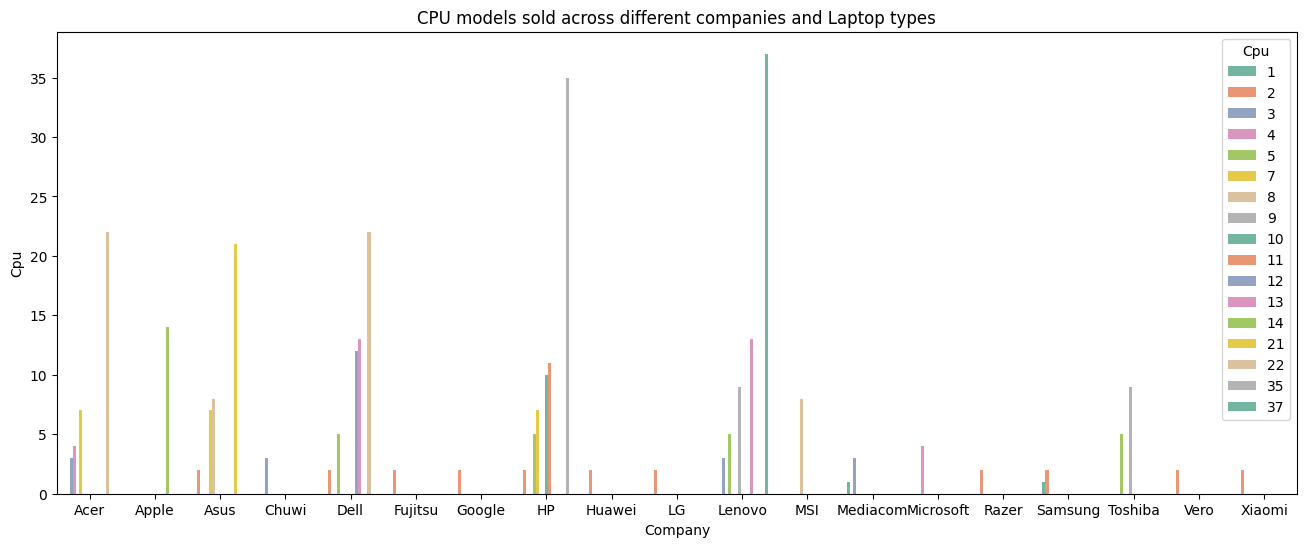

In [434]:
plt.figure(figsize=(16, 6))
sns.barplot(data=Company_models,x="Company",y="Cpu",hue="Cpu",palette="Set2")
plt.title("CPU models sold across different companies and Laptop types")
plt.show()

In [192]:
CPU=Laptop_sales["Cpu"].value_counts().head(10)
CPU

Cpu
Intel Core i5 7200U 2.5GHz     183
Intel Core i7 7700HQ 2.8GHz    142
Intel Core i7 7500U 2.7GHz     128
Intel Core i7 8550U 1.8GHz      72
Intel Core i5 8250U 1.6GHz      68
Intel Core i5 6200U 2.3GHz      66
Intel Core i3 6006U 2GHz        62
Intel Core i7 6500U 2.5GHz      49
Intel Core i7 6700HQ 2.6GHz     43
Intel Core i3 7100U 2.4GHz      37
Name: count, dtype: int64

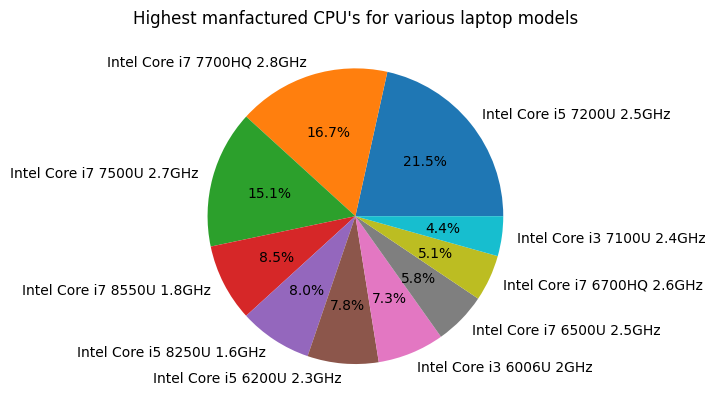

In [196]:
plt.pie(x=CPU,labels=CPU.index,autopct="%1.1f%%")
plt.title("Highest manfactured CPU's for various laptop models")
plt.show()

In [206]:
Laptop_sales_cpu=Laptop_sales[Laptop_sales["Cpu"]=="Intel Core i5 7200U 2.5GHz"]
Laptop_sales_cpu

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Total_items_sold
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000,2645
10,HP,Notebook,15.6,1366x768,Intel Core i5 7200U 2.5GHz,4GB,500GB HDD,Intel HD Graphics 620,No OS,1.86kg,20986.9920,2903
38,HP,Notebook,15.6,1366x768,Intel Core i5 7200U 2.5GHz,4GB,1TB HDD,Intel HD Graphics 620,Windows 10,1.86kg,26037.4032,2711
42,Asus,Notebook,15.6,1366x768,Intel Core i5 7200U 2.5GHz,8GB,1TB HDD,Nvidia GeForce 940MX,Linux,2.3kg,27864.9072,2654
48,Dell,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,4GB,256GB SSD,AMD Radeon R5 M430,Windows 10,2.3kg,34045.9200,2536
...,...,...,...,...,...,...,...,...,...,...,...,...
1213,Dell,2 in 1 Convertible,15.6,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,Windows 10,2.191kg,53226.7200,2000
1217,Lenovo,Notebook,17.3,1600x900,Intel Core i5 7200U 2.5GHz,8GB,1TB HDD,Intel HD Graphics 620,No OS,2.8kg,28717.9200,2707
1227,Dell,Notebook,15.6,1366x768,Intel Core i5 7200U 2.5GHz,4GB,1TB HDD,Intel HD Graphics 520,Linux,2.18kg,27804.7008,2670
1246,Dell,Notebook,14.0,1366x768,Intel Core i5 7200U 2.5GHz,4GB,500GB HDD,Intel HD Graphics 620,Windows 10,1.6kg,46620.0000,2505


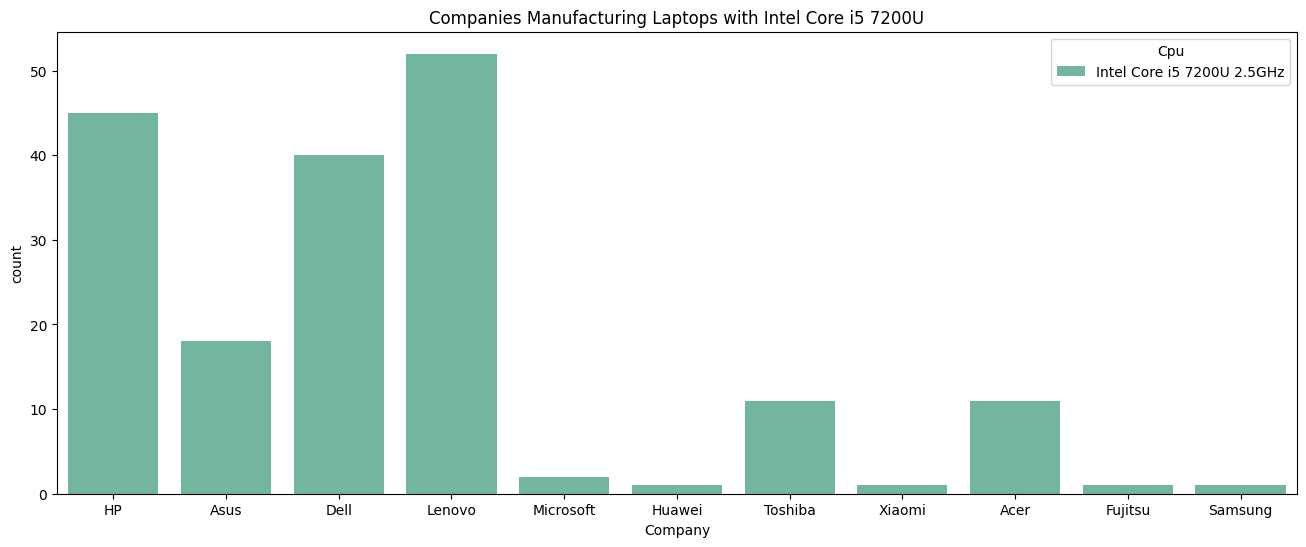

In [217]:
plt.figure(figsize=(16, 6))
sns.countplot(data=Laptop_sales_cpu,x="Company",hue="Cpu",palette="Set2")
plt.title("Companies Manufacturing Laptops with Intel Core i5 7200U")
plt.show()


In [218]:
Laptop_sales.dtypes

Company              object
TypeName             object
Inches              float64
ScreenResolution     object
Cpu                  object
Ram                  object
Memory               object
Gpu                  object
OpSys                object
Weight               object
Price               float64
Total_items_sold      int64
dtype: object

In [288]:
Laptop_price=pd.DataFrame(Laptop_sales.groupby(by=["Company"])["Price_million"].sum().sort_values(ascending=False))
Laptop_price

,Price_million
Company,
Dell,181.490365
Lenovo,168.410184
HP,152.190228
Asus,91.996903
MSI,48.661711
Acer,34.396454
Toshiba,31.371264
Apple,17.501505
Razer,12.479774


C:\Users\Q848957\AppData\Local\Temp\ipykernel_29680\4057433745.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=Laptop_price,x="Company",y="Price_million", palette="Set2")


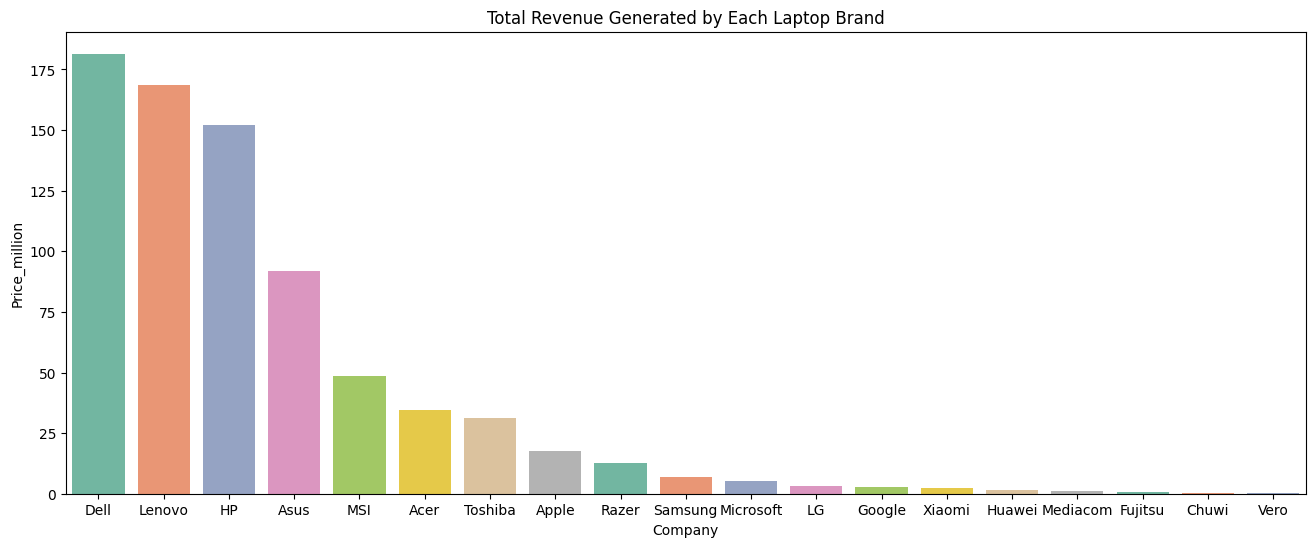

In [296]:
plt.figure(figsize=(16, 6))
sns.barplot(data=Laptop_price,x="Company",y="Price_million", palette="Set2")
plt.title("Total Revenue Generated by Each Laptop Brand")
plt.show()

C:\Users\Q848957\AppData\Local\Temp\ipykernel_29680\3245587025.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.catplot(data=Laptop_price,x="Company",y="Price_million", palette="Set2")


<Figure size 1600x600 with 0 Axes>

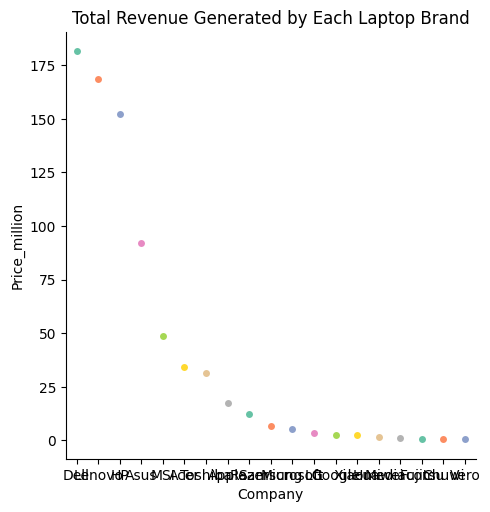

In [320]:
plt.figure(figsize=(16, 6))
sns.catplot(data=Laptop_price,x="Company",y="Price_million", palette="Set2")
plt.title("Total Revenue Generated by Each Laptop Brand")
plt.show()

In [299]:
Laptop_sales_price=pd.DataFrame(Laptop_sales.groupby(by=["Company","Cpu"])["Price_million"].sum().sort_values(ascending=False))
Price_ten=Laptop_sales_price.head(15)
Price_ten

,,Price_million
Company,Cpu,
Dell,Intel Core i7 7700HQ 2.8GHz,39.536403
Lenovo,Intel Core i7 7500U 2.7GHz,29.830103
MSI,Intel Core i7 7700HQ 2.8GHz,27.008266
Lenovo,Intel Core i5 7200U 2.5GHz,26.081631
Asus,Intel Core i7 7700HQ 2.8GHz,25.085769
HP,Intel Core i5 7200U 2.5GHz,22.762468
Dell,Intel Core i7 8550U 1.8GHz,21.698083
HP,Intel Core i7 7500U 2.7GHz,18.120219
Dell,Intel Core i5 7200U 2.5GHz,18.097426


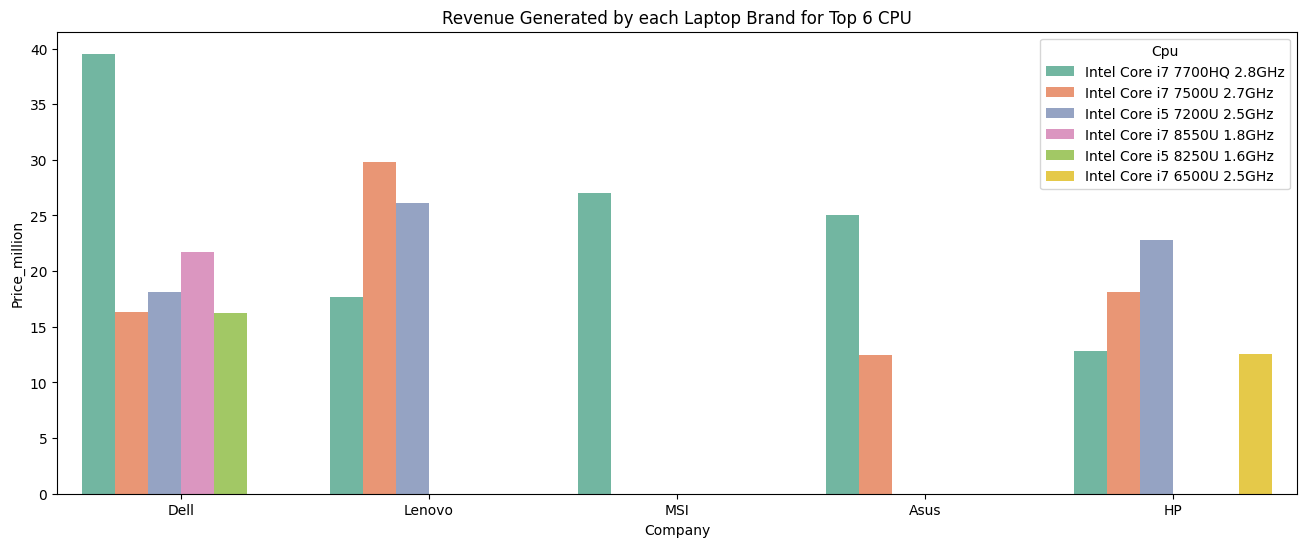

In [301]:
plt.figure(figsize=(16, 6))
sns.barplot(data=Price_ten,x="Company",y="Price_million",hue="Cpu", palette="Set2")
plt.title("Revenue Generated by each Laptop Brand for Top 6 CPU")
plt.show()

<Axes: xlabel='Company', ylabel='Price_million'>

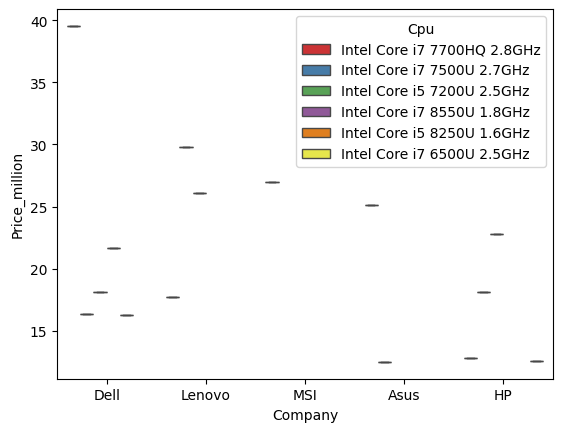

In [311]:
sns.boxplot(data=Price_ten,x="Company",y="Price_million",hue="Cpu",palette="Set1")

<Figure size 1600x600 with 0 Axes>

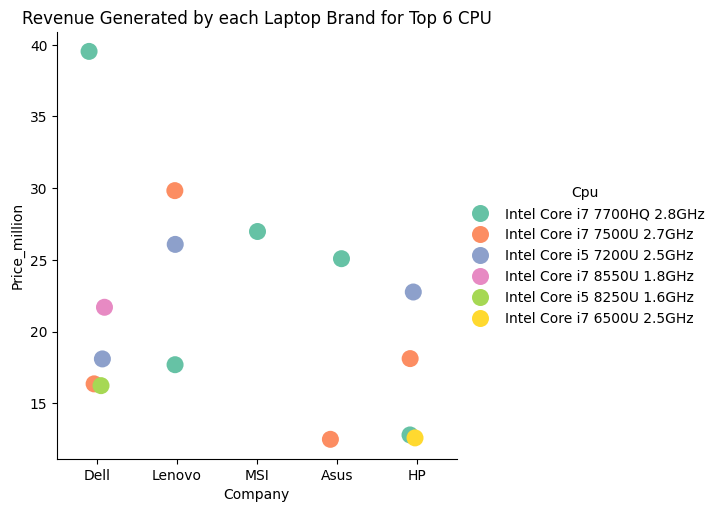

In [314]:
plt.figure(figsize=(16, 6))
sns.catplot(data=Price_ten,x="Company",y="Price_million",hue="Cpu", palette="Set2",s=150)
plt.title("Revenue Generated by each Laptop Brand for Top 6 CPU")
plt.show()

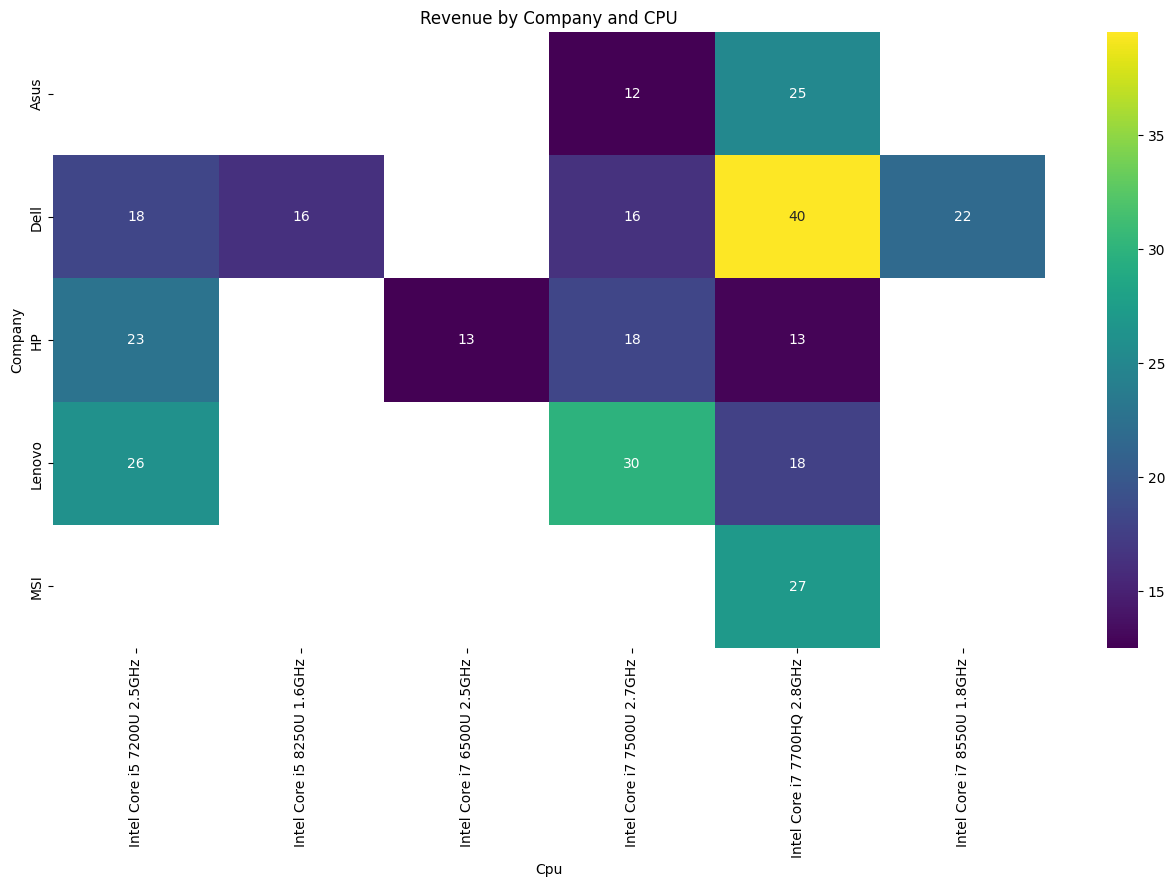

In [319]:
heat_data = pd.pivot_table(
Price_ten,
index="Company",
columns="Cpu",
values="Price_million",
aggfunc="sum"
)
plt.figure(figsize=(16,8))
sns.heatmap(
heat_data,
cmap="viridis",
annot=True
)
plt.title("Revenue by Company and CPU")
plt.show()

In [325]:
Laptop_sales_Cpu=Laptop_sales.groupby("Cpu")["Price"].sum().sort_values(ascending=False).head(10)
Laptop_sales_Cpu

Cpu
Intel Core i7 7700HQ 2.8GHz    13295662.22
Intel Core i7 7500U 2.7GHz      9165041.78
Intel Core i5 7200U 2.5GHz      8985879.27
Intel Core i7 8550U 1.8GHz      4624300.14
Intel Core i7 6700HQ 2.6GHz     3811573.94
Intel Core i5 6200U 2.3GHz      3658641.71
Intel Core i5 8250U 1.6GHz      3416779.80
Intel Core i7 6500U 2.5GHz      3338855.67
Intel Core i5 7300HQ 2.5GHz     1923038.76
Intel Core i7 6600U 2.6GHz      1747389.53
Name: Price, dtype: float64

In [341]:
plt.figure(figsize=(16,5))
plt.pie(Laptop_sales_Cpu,labels=Laptop_sales_Cpu["Price"], autopct="%1.1f%%")
plt.title("Most sold laptop based on CPU")
plt.show()

KeyError: 'Price'

<Figure size 1600x500 with 0 Axes>

In [ ]:
sns.boxenplot

,,Price_million
Company,Cpu,
Dell,Intel Core i7 7700HQ 2.8GHz,39.536403
Lenovo,Intel Core i7 7500U 2.7GHz,29.830103
MSI,Intel Core i7 7700HQ 2.8GHz,27.008266
Lenovo,Intel Core i5 7200U 2.5GHz,26.081631
Asus,Intel Core i7 7700HQ 2.8GHz,25.085769
...,...,...
Samsung,Intel Celeron Dual Core N3060 1.6GHz,0.143323
Mediacom,Intel Atom Z8350 1.92GHz,0.141192
Chuwi,Intel Atom x5-Z8350 1.44GHz,0.132614


In [358]:
Laptop_sales_resolution=Laptop_sales.groupby(by=["Company","Cpu"])["Price_million"].sum().sort_values(ascending=False)

In [370]:
Laptop_sales_resolution=Laptop_sales[Laptop_sales["Cpu"].isin(["Intel Core i7 7700HQ 2.8GHz","Intel Core i7 7500U 2.7GHz","Intel Core i5 7200U 2.5GHz", "Intel Core i7 8550U 1.8GHz", "Intel Core i5 8250U 1.6GHz", "Intel Core i7 6500U 2.5GHz"])]

In [381]:
Laptop_sales_resolution
SR=Laptop_sales_resolution["ScreenResolution"].value_counts().head(10)
GPU=Laptop_sales_resolution["Gpu"].value_counts()

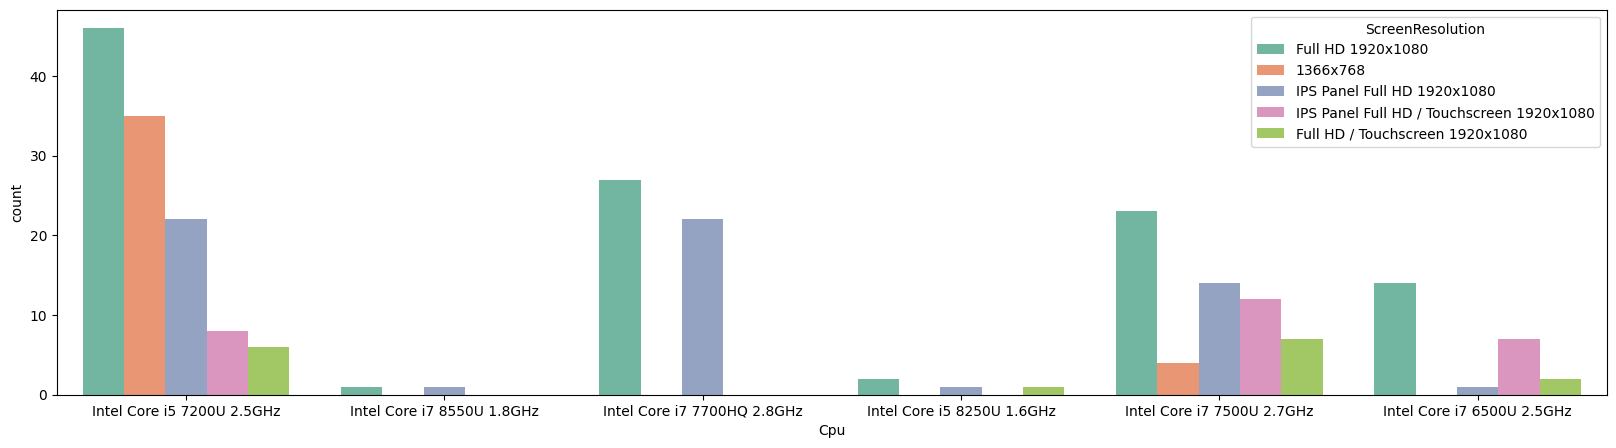

In [427]:
plt.figure(figsize=(20,5))
sns.countplot(data=Laptop_sales_resolution, x="Cpu",hue="ScreenResolution", palette="Set2")
plt.show()


In [399]:
Laptop_sales_resolution2=Laptop_sales_resolution.sort_values(by=["Price","Cpu","ScreenResolution","Gpu"])

In [400]:
Laptop_sales_resolution2

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Total_items_sold,Price_million
10,HP,Notebook,15.6,1366x768,Intel Core i5 7200U 2.5GHz,4GB,500GB HDD,Intel HD Graphics 620,No OS,1.86kg,20986.99,2903,0.209870
446,Acer,Notebook,15.6,1366x768,Intel Core i5 7200U 2.5GHz,4GB,500GB HDD,Intel HD Graphics 620,Linux,2.4kg,23539.10,2687,0.235391
627,Lenovo,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 620,No OS,2.2kg,24935.04,2732,0.249350
1192,HP,Notebook,15.6,1366x768,Intel Core i5 7200U 2.5GHz,4GB,500GB HDD,Intel HD Graphics 620,Windows 10,1.86kg,25840.80,2744,0.258408
38,HP,Notebook,15.6,1366x768,Intel Core i5 7200U 2.5GHz,4GB,1TB HDD,Intel HD Graphics 620,Windows 10,1.86kg,26037.40,2711,0.260374
...,...,...,...,...,...,...,...,...,...,...,...,...,...
968,Dell,Gaming,17.3,IPS Panel Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,32GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1070,Windows 10,4.42kg,167778.72,532,1.677787
955,Dell,Gaming,17.3,IPS Panel 4K Ultra HD 3840x2160,Intel Core i7 7700HQ 2.8GHz,16GB,512GB SSD + 1TB HDD,Nvidia GeForce GTX 1070,Windows 10,4.36kg,168045.12,515,1.680451
1231,Razer,Gaming,14.0,Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,16GB,1TB SSD,Nvidia GeForce GTX 1060,Windows 10,1.95kg,186426.72,215,1.864267
780,Dell,Gaming,17.3,IPS Panel Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,32GB,1TB SSD + 1TB HDD,Nvidia GeForce GTX 1070M,Windows 10,4.42kg,191211.26,221,1.912113


In [413]:
Laptop_sales_Gpu_price=Laptop_sales.groupby(by=["Gpu"])["Price_million"].sum().sort_values(ascending=False)

In [414]:
Laptop_sales_Gpu_price.head(5)

Gpu
Intel HD Graphics 620      165.040304
Intel HD Graphics 520      101.866442
Nvidia GeForce GTX 1060     46.460965
Intel UHD Graphics 620      42.255436
Nvidia GeForce GTX 1070     40.666045
Name: Price_million, dtype: float64

In [415]:
Laptop_sales_resolution = Laptop_sales[
    (Laptop_sales["Cpu"].isin([
        "Intel Core i7 7700HQ 2.8GHz", 
        "Intel Core i7 7500U 2.7GHz", 
        "Intel Core i5 7200U 2.5GHz", 
        "Intel Core i7 8550U 1.8GHz", 
        "Intel Core i5 8250U 1.6GHz", 
        "Intel Core i7 6500U 2.5GHz"
    ])) &
    (Laptop_sales["ScreenResolution"].isin([
        "Full HD 1920x1080", 
        "IPS Panel Full HD 1920x1080", 
        "1366x768", 
        "Full HD / Touchscreen 1920x1080", 
        "IPS Panel Full HD / Touchscreen 1920x1080"
    ])) &

    (Laptop_sales["Gpu"].isin([
        "Intel HD Graphics 620", 
        "Intel HD Graphics 520", 
        "Nvidia GeForce GTX 1060", 
        "Nvidia GeForce GTX 1060", 
        "Nvidia GeForce GTX 1070"
    ]))
    
]

In [416]:
Laptop_sales_resolution

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Total_items_sold,Price_million
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.00,2645,0.306360
10,HP,Notebook,15.6,1366x768,Intel Core i5 7200U 2.5GHz,4GB,500GB HDD,Intel HD Graphics 620,No OS,1.86kg,20986.99,2903,0.209870
24,HP,Ultrabook,15.6,Full HD 1920x1080,Intel Core i7 8550U 1.8GHz,8GB,256GB SSD,Intel HD Graphics 620,Windows 10,1.91kg,35111.52,1932,0.351115
38,HP,Notebook,15.6,1366x768,Intel Core i5 7200U 2.5GHz,4GB,1TB HDD,Intel HD Graphics 620,Windows 10,1.86kg,26037.40,2711,0.260374
41,Dell,Gaming,15.6,IPS Panel Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1060,Windows 10,2.65kg,79866.72,1201,0.798667
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1246,Dell,Notebook,14.0,1366x768,Intel Core i5 7200U 2.5GHz,4GB,500GB HDD,Intel HD Graphics 620,Windows 10,1.6kg,46620.00,2505,0.466200
1248,Lenovo,Notebook,15.6,IPS Panel Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,2.3kg,30529.44,2606,0.305294
1270,Lenovo,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,33992.64,2395,0.339926
1284,Lenovo,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,33992.64,2245,0.339926


In [429]:
Laptop_sales_resolution.groupby(["Company","Cpu"])["Price_million"].sum().sort_values(ascending=False)

Company  Cpu                        
Lenovo   Intel Core i7 7500U 2.7GHz     18.415923
         Intel Core i5 7200U 2.5GHz     18.210571
HP       Intel Core i5 7200U 2.5GHz     17.566464
MSI      Intel Core i7 7700HQ 2.8GHz    17.548572
Dell     Intel Core i7 7700HQ 2.8GHz    11.278657
         Intel Core i5 7200U 2.5GHz     10.507115
Asus     Intel Core i7 7700HQ 2.8GHz    10.304299
HP       Intel Core i7 7500U 2.7GHz     10.123733
         Intel Core i7 6500U 2.5GHz      8.712303
Asus     Intel Core i7 7500U 2.7GHz      6.938548
Toshiba  Intel Core i5 7200U 2.5GHz      6.898694
         Intel Core i7 7500U 2.7GHz      5.364230
Lenovo   Intel Core i7 7700HQ 2.8GHz     5.158570
Razer    Intel Core i7 7700HQ 2.8GHz     4.793602
Asus     Intel Core i5 7200U 2.5GHz      3.852250
Lenovo   Intel Core i7 6500U 2.5GHz      3.712812
Toshiba  Intel Core i7 6500U 2.5GHz      3.402461
Dell     Intel Core i7 7500U 2.7GHz      3.169132
HP       Intel Core i7 7700HQ 2.8GHz     2.928802
Samsung  Inte